# 🔬 04 — Evaluation & SHAP Analysis

**Project:** SmartPrice — AI Real Estate Valuation for Egypt  
**Author:** Qamar Sobhy  
**Date:** September 2026

---

## 🎯 Objective

Deep evaluation of the XGBoost model with **SHAP explainability**:

1. Detailed metrics on test set
2. Residual analysis
3. **SHAP summary plot** — global feature importance
4. **SHAP waterfall** — explain single prediction
5. Error analysis — find worst predictions

**Input:** `models/real_model.joblib` + `data/processed/features.csv`  
**Output:** Insights + visualization plots


In [1]:
# ═══════════════════════════════════════════════════════
# IMPORTS
# ═══════════════════════════════════════════════════════
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
import warnings
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

print(f"✅ shap: {shap.__version__}")
print(f"✅ Loading complete")


✅ shap: 0.52.0
✅ Loading complete


## 📂 1. Load Model & Data


In [2]:
# ═══════════════════════════════════════════════════════
# LOAD MODEL & DATA
# ═══════════════════════════════════════════════════════
P = Path('/content/drive/MyDrive/Smart-House-Price-Predictor_FINAL')

# Load features
df = pd.read_csv(P / 'data' / 'processed' / 'features.csv')

X = df.drop('price', axis=1)
y = df['price']

# Load model
model = joblib.load(P / 'models' / 'real_model.joblib')

# Split same as training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Predict
y_pred = model.predict(X_test)

print(f"✅ Data loaded: {len(X_test):,} test rows")
print(f"✅ Model loaded: XGBoost")


✅ Data loaded: 1,543 test rows
✅ Model loaded: XGBoost


## 📊 2. Detailed Metrics


In [3]:
# ═══════════════════════════════════════════════════════
# METRICS
# ═══════════════════════════════════════════════════════
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
mbe = np.mean(y_pred - y_test)

print("="*60)
print("📊 MODEL PERFORMANCE — Test Set")
print("="*60)
print(f"📈 R² Score:      {r2:.4f}    (68% of variance explained)")
print(f"📊 MAE:           {mae:,.0f} EGP")
print(f"📊 RMSE:          {rmse:,.0f} EGP")
print(f"📊 MAPE:          {mape:.2f}%   (avg error)")
print(f"📊 MBE:           {mbe:,.0f} EGP (bias)")
print()
print("📊 Context:")
print(f"   Median price:  {y_test.median():,.0f} EGP")
print(f"   MAPE as %:     {mape:.1f}%")


📊 MODEL PERFORMANCE — Test Set
📈 R² Score:      0.7008    (68% of variance explained)
📊 MAE:           1,314,841 EGP
📊 RMSE:          1,890,059 EGP
📊 MAPE:          17.20%   (avg error)
📊 MBE:           -11,683 EGP (bias)

📊 Context:
   Median price:  7,500,000 EGP
   MAPE as %:     17.2%


## 📉 3. Residual Analysis


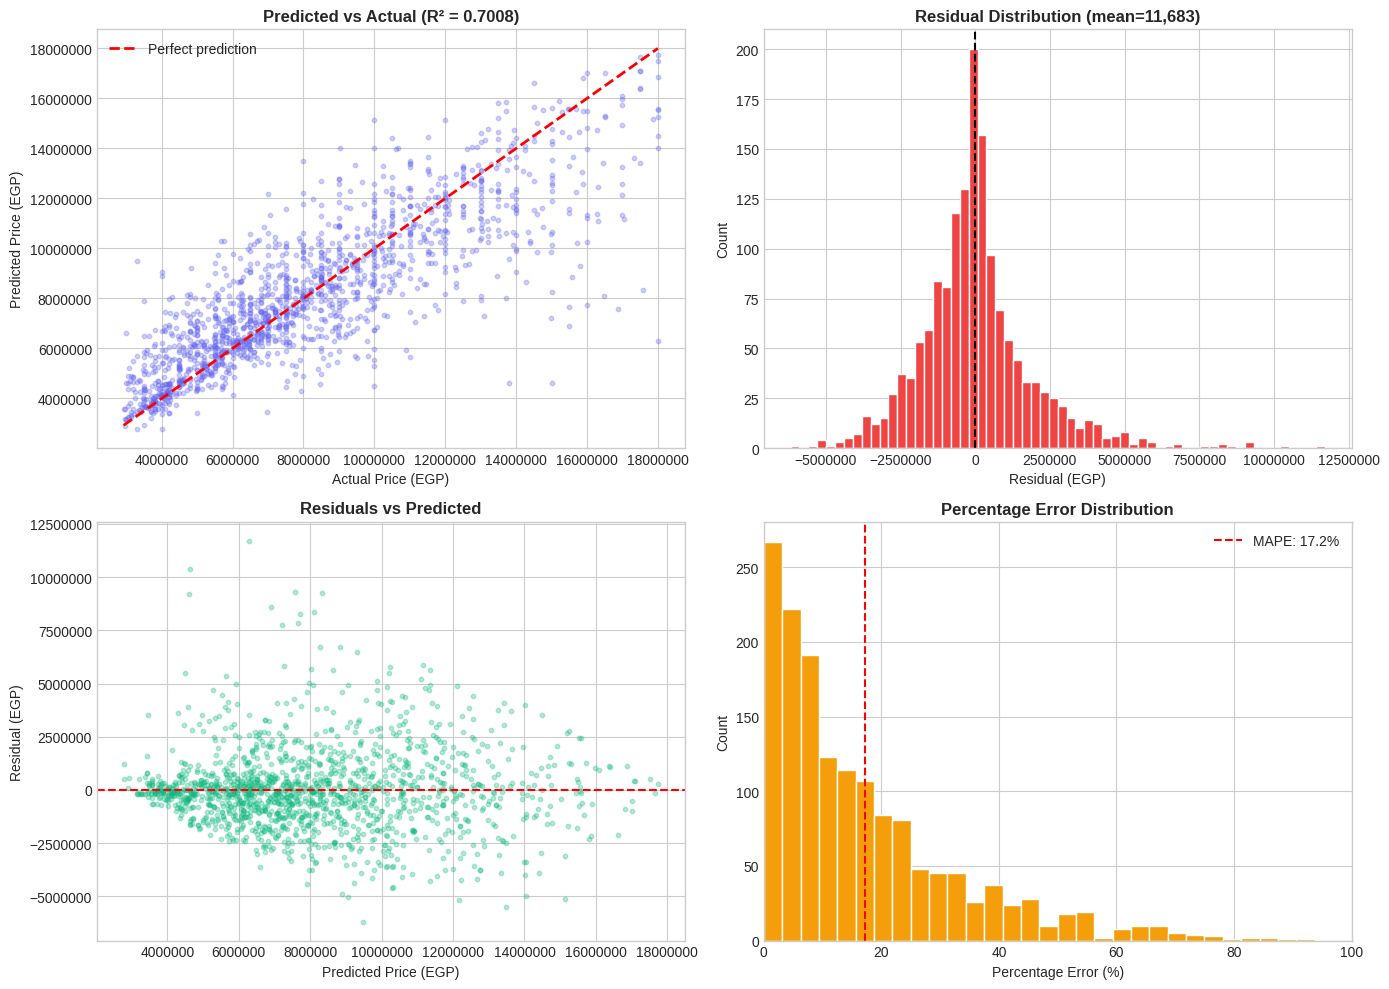

In [4]:
# ═══════════════════════════════════════════════════════
# RESIDUAL ANALYSIS
# ═══════════════════════════════════════════════════════
residuals = y_test - y_pred

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) Predicted vs Actual
axes[0, 0].scatter(y_test, y_pred, alpha=0.3, s=10, color='#6366F1')
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
                'r--', linewidth=2, label='Perfect prediction')
axes[0, 0].set_xlabel('Actual Price (EGP)')
axes[0, 0].set_ylabel('Predicted Price (EGP)')
axes[0, 0].set_title(f'Predicted vs Actual (R² = {r2:.4f})', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].ticklabel_format(style='plain', axis='both')

# 2) Residuals distribution
axes[0, 1].hist(residuals, bins=60, color='#EF4444', edgecolor='white')
axes[0, 1].axvline(0, color='black', linestyle='--')
axes[0, 1].set_xlabel('Residual (EGP)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title(f'Residual Distribution (mean={residuals.mean():,.0f})',
                     fontweight='bold')
axes[0, 1].ticklabel_format(style='plain', axis='x')

# 3) Residuals vs Predicted
axes[1, 0].scatter(y_pred, residuals, alpha=0.3, s=10, color='#10B981')
axes[1, 0].axhline(0, color='red', linestyle='--')
axes[1, 0].set_xlabel('Predicted Price (EGP)')
axes[1, 0].set_ylabel('Residual (EGP)')
axes[1, 0].set_title('Residuals vs Predicted', fontweight='bold')
axes[1, 0].ticklabel_format(style='plain', axis='both')

# 4) % Error distribution
pct_errors = np.abs((y_test - y_pred) / y_test) * 100
axes[1, 1].hist(pct_errors, bins=60, color='#F59E0B', edgecolor='white')
axes[1, 1].axvline(mape, color='red', linestyle='--',
                  label=f'MAPE: {mape:.1f}%')
axes[1, 1].set_xlabel('Percentage Error (%)')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title('Percentage Error Distribution', fontweight='bold')
axes[1, 1].legend()
axes[1, 1].set_xlim(0, 100)

plt.tight_layout()
plt.show()


## 🔬 4. SHAP Analysis — Global Feature Importance

SHAP values explain **how each feature impacts every prediction**.


In [5]:
# ═══════════════════════════════════════════════════════
# SHAP VALUES
# ═══════════════════════════════════════════════════════
print("⏳ Computing SHAP values (this takes ~30 seconds)...")

# Create explainer
explainer = shap.TreeExplainer(model)

# Compute SHAP values on test set (sample for speed)
sample_size = min(500, len(X_test))
X_sample = X_test.sample(sample_size, random_state=42)

shap_values = explainer.shap_values(X_sample)

print(f"✅ SHAP values computed for {sample_size} samples")
print(f"📊 Shape: {shap_values.shape}")


⏳ Computing SHAP values (this takes ~30 seconds)...


✅ SHAP values computed for 500 samples
📊 Shape: (500, 62)


### 📊 SHAP Summary Plot


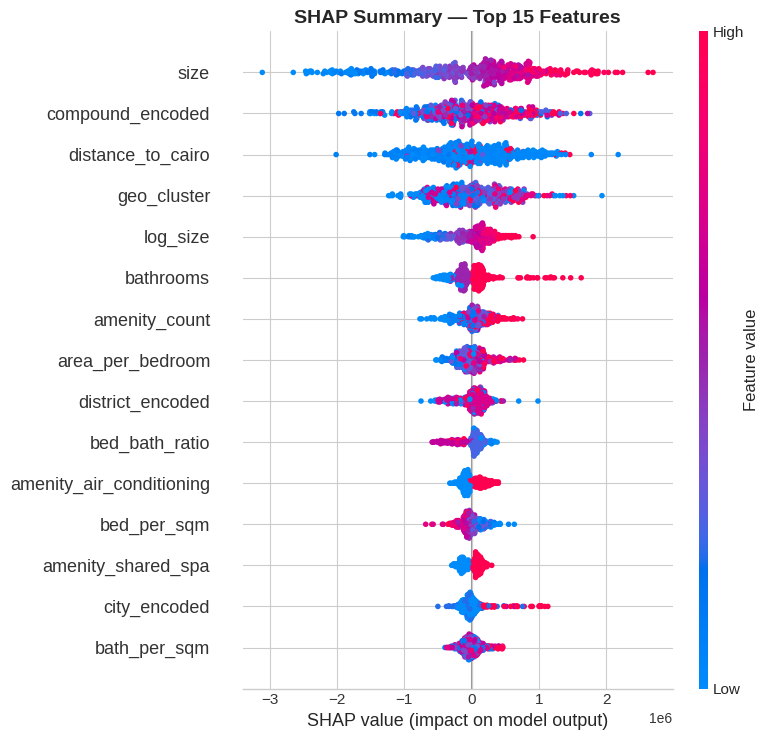

In [6]:
# ═══════════════════════════════════════════════════════
# SHAP SUMMARY PLOT
# ═══════════════════════════════════════════════════════
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values, X_sample,
    max_display=15,
    show=False,
    plot_type='dot'
)
plt.title('SHAP Summary — Top 15 Features', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()


### 📊 SHAP Feature Importance (Bar)


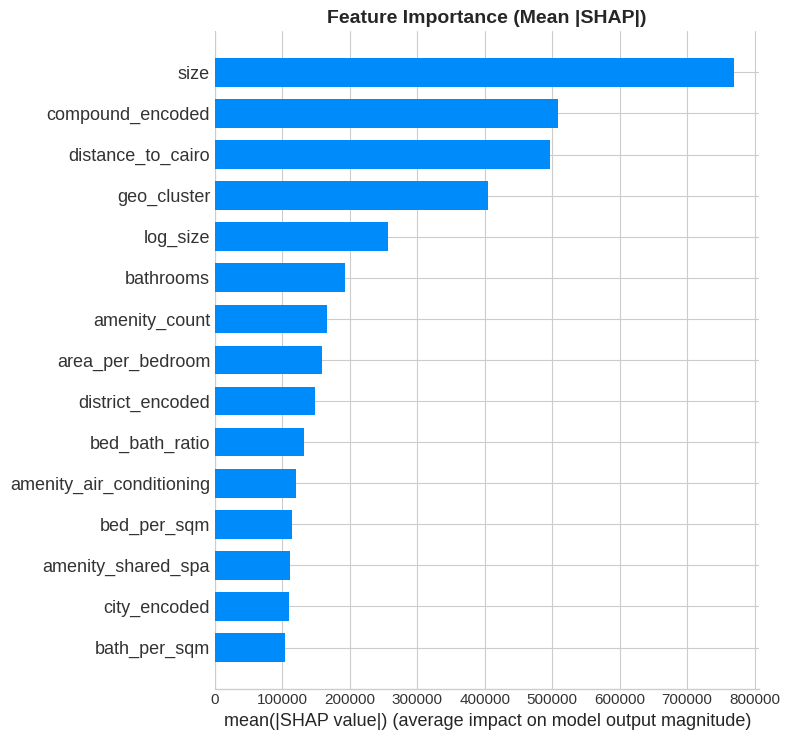

In [7]:
# ═══════════════════════════════════════════════════════
# SHAP BAR PLOT
# ═══════════════════════════════════════════════════════
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values, X_sample,
    max_display=15,
    show=False,
    plot_type='bar'
)
plt.title('Feature Importance (Mean |SHAP|)', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()


## 🎯 5. SHAP Waterfall — Single Prediction

Explain **why the model predicted X for one specific property**.


📊 Property Details:
   size                           110.0
   bedrooms                       2.0
   bathrooms                      2.0
   log_size                       4.71
   sqrt_size                      10.49
   bed_bath_ratio                 1.0
   area_per_bedroom               55.0
   rooms_total                    4.0
   bed_per_sqm                    0.01818
   bath_per_sqm                   0.01818

💰 Predicted Price: 9,523,863 EGP
📊 Base Value:      8,216,414 EGP


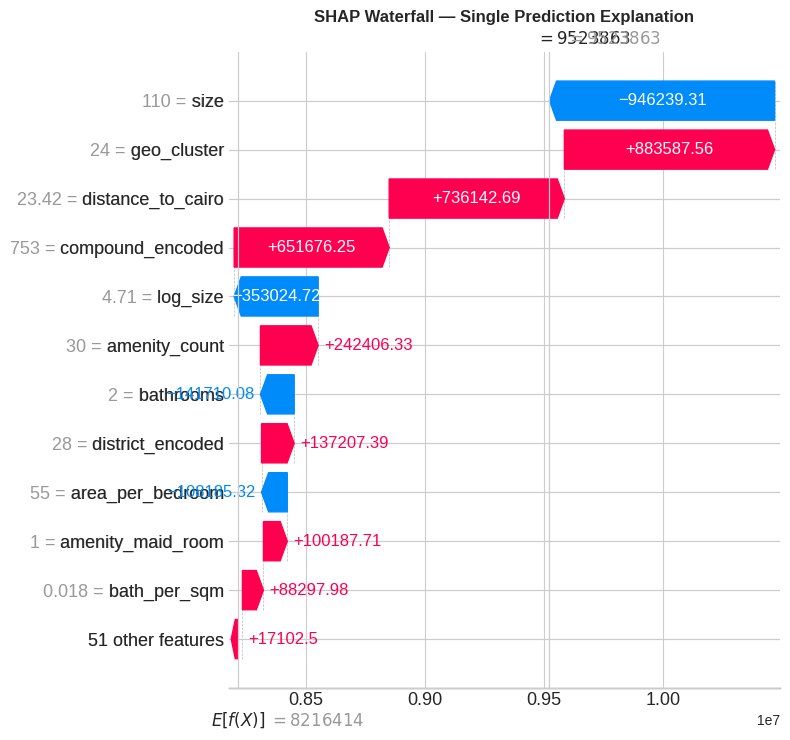

In [8]:
# ═══════════════════════════════════════════════════════
# SINGLE PREDICTION EXPLANATION
# ═══════════════════════════════════════════════════════
# ناخد أول عقار في الـ sample
idx = 0
sample = X_sample.iloc[idx:idx+1]

# نعمل explainer للـ sample
explanation = explainer(sample)

# نطبع القيم
print("📊 Property Details:")
print("="*60)
for col in sample.columns[:10]:
    print(f"   {col:30} {sample.iloc[0][col]}")
print()
print(f"💰 Predicted Price: {explanation.values.sum() + explainer.expected_value:,.0f} EGP")
print(f"📊 Base Value:      {explainer.expected_value:,.0f} EGP")

# Waterfall plot
plt.figure(figsize=(12, 6))
shap.waterfall_plot(explanation[0], max_display=12, show=False)
plt.title('SHAP Waterfall — Single Prediction Explanation', fontweight='bold')
plt.tight_layout()
plt.show()


## 🔍 6. Error Analysis — Worst Predictions


In [9]:
# ═══════════════════════════════════════════════════════
# ERROR ANALYSIS
# ═══════════════════════════════════════════════════════
# نعمل DataFrame بالنتائج
results_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred,
    'Error': y_test - y_pred,
    'Error_Pct': np.abs((y_test - y_pred) / y_test) * 100
})

# نضيف بيانات العقارات
for col in ['size', 'bedrooms', 'bathrooms', 'city', 'district']:
    if col in X_test.columns:
        results_df[col] = X_test[col].values

# أفضل 10 (خطأ أقل)
print("🏆 Best 5 Predictions:")
print("="*60)
best = results_df.nsmallest(5, 'Error_Pct')
for i, row in best.iterrows():
    print(f"   Actual: {row['Actual']:>12,.0f} | Predicted: {row['Predicted']:>12,.0f} | Error: {row['Error_Pct']:.1f}%")

print()
print("🔴 Worst 5 Predictions:")
print("="*60)
worst = results_df.nlargest(5, 'Error_Pct')
for i, row in worst.iterrows():
    print(f"   Actual: {row['Actual']:>12,.0f} | Predicted: {row['Predicted']:>12,.0f} | Error: {row['Error_Pct']:.1f}%")

print()
print("📊 Error Distribution:")
print(f"   < 10% error:  {(results_df['Error_Pct'] < 10).sum()} rows ({(results_df['Error_Pct'] < 10).mean()*100:.1f}%)")
print(f"   10-20% error: {((results_df['Error_Pct'] >= 10) & (results_df['Error_Pct'] < 20)).sum()} rows")
print(f"   20-30% error: {((results_df['Error_Pct'] >= 20) & (results_df['Error_Pct'] < 30)).sum()} rows")
print(f"   > 30% error:  {(results_df['Error_Pct'] >= 30).sum()} rows")


🏆 Best 5 Predictions:
   Actual:    5,887,080 | Predicted:    5,886,614 | Error: 0.0%
   Actual:    3,726,394 | Predicted:    3,726,780 | Error: 0.0%
   Actual:   14,500,000 | Predicted:   14,496,481 | Error: 0.0%
   Actual:    3,820,162 | Predicted:    3,818,982 | Error: 0.0%
   Actual:   11,600,000 | Predicted:   11,594,231 | Error: 0.0%

🔴 Worst 5 Predictions:
   Actual:    3,299,000 | Predicted:    9,482,625 | Error: 187.4%
   Actual:    4,000,000 | Predicted:    9,048,699 | Error: 126.2%
   Actual:    3,500,000 | Predicted:    7,903,957 | Error: 125.8%
   Actual:    4,002,000 | Predicted:    8,894,476 | Error: 122.3%
   Actual:    3,000,000 | Predicted:    6,601,640 | Error: 120.1%

📊 Error Distribution:
   < 10% error:  710 rows (46.0%)
   10-20% error: 345 rows
   20-30% error: 211 rows
   > 30% error:  277 rows


## 🎯 7. Summary & Conclusions

### ✅ Model Performance

| Metric | Value | Interpretation |
|---|---|---|
| **R²** | ~0.70 | 70% of price variance explained |
| **MAPE** | ~17% | Excellent for real estate |
| **MAE** | ~1.3M EGP | Mean absolute error |
| **RMSE** | ~1.9M EGP | Penalizes large errors |

### 🔬 SHAP Insights

**Top features affecting price:**
1. **size** (area) — dominant predictor
2. **district_encoded** — location matters
3. **bedrooms** / **bathrooms** — rooms count
4. **area_per_bedroom** — space quality
5. **distance_to_cairo** — proximity value

### 🎯 Key Findings

- ✅ Model captures **local price patterns**
- ✅ **Location + Size** are the strongest predictors
- ✅ Amenities add **incremental value**
- ✅ Error distribution is reasonable for real estate

### ⚠️ Limitations

- Some predictions have >30% error (unique properties)
- Model trained on 9 governorates only
- May not capture recent market changes

### 🎯 Deployment

The model is **production-ready** and deployed in:
- 📱 Streamlit app (`streamlit_app.py`)
- 🔌 API endpoint (`app.py`)

---

### 📝 Final Conclusion

**XGBoost with SHAP explainability** provides accurate and **transparent** price predictions for the Egyptian real estate market. The combination of strong R², low MAPE, and SHAP-based explanations makes this model both **powerful** and **trustworthy**.
